# 02 · Baseline Models & Targeting Policies

**Research question 2:** *Does uplift-based targeting outperform propensity-based targeting?* This notebook sets up the evaluation framework and the baselines that any advanced model must beat.

| Policy | Who gets the e-mail | What it needs |
|---|---|---|
| **No campaign** | nobody | — (reference point, incremental value = 0) |
| **Treat all** | everyone | the ATE |
| **Random** | a random share *φ* | the ATE (expected value = φ × ATE) |
| **Purchase propensity** | top *φ* by P(purchase \| X, emailed) | a standard response model |
| **T-learner** | top *φ* by estimated uplift μ₁(x) − μ₀(x) | two outcome models |

> **Two "propensities".** *Purchase propensity* is a customer's predicted probability of buying, which is what a conventional targeting model scores. The *assignment probability* e = P(e-mail) is fixed at ≈ 1/3 per arm by the experiment design, and the evaluation estimators use it as known.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score

from src import config, data, evaluation, inference, pipeline, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

df = data.load_raw()
X = data.build_features(df)
CAMPAIGN_KEYS = list(config.CAMPAIGNS)
PRIMARY = config.PRIMARY_CAMPAIGN

## 1 · Partitions

* **Test (20%)**: locked away until notebook 04, after every modelling choice is frozen.
* **Development (80%)**: split into 5 stratified folds for **cross-fitting**. Each customer is scored by models that never saw them, so every development customer contributes an honest out-of-fold prediction.

Notebook 01 showed that a single 20% validation split has a spend MDE about twice the size of the effect. Cross-fitting uses all 51,200 development customers for evaluation, which roughly halves the standard error of model comparisons relative to one validation split.

Stratification is by arm × conversion, so the rare buyers are spread evenly across partitions.

In [2]:
split = data.assign_splits(df, seed=config.SEED)
folds = data.assign_folds(df, split == "dev", seed=config.SEED)
dev = (split == "dev").to_numpy()
config.ARTIFACTS_DIR.mkdir(exist_ok=True)
pd.DataFrame({"split": split, "fold": folds}).to_csv(config.ARTIFACTS_DIR / "splits.csv")

part = df.assign(partition=np.where(dev, "dev fold " + folds.astype(str), "test"))
pd.crosstab(part["partition"], part["segment"], margins=True).join(
    part.groupby("partition")["conversion"].sum().rename("buyers"))

,Mens E-Mail,No E-Mail,Womens E-Mail,All,buyers
partition,,,,,
dev fold 0,3409,3409,3422,10240,93.0000
dev fold 1,3410,3409,3421,10240,92.0000
dev fold 2,3408,3409,3423,10240,93.0000
dev fold 3,3410,3409,3421,10240,92.0000
dev fold 4,3409,3409,3422,10240,93.0000
test,4261,4261,4278,12800,115.0000
All,21307,21306,21387,64000,NaN


## 2 · Evaluation framework: AIPW scores

Individual treatment effects are never observed. A customer either received the e-mail or did not. Policies are therefore evaluated with the **doubly robust (AIPW)** score, computed per customer *i* and arm *k*:

$$\Gamma_{ik} = \hat\mu_k(X_i) - \hat\mu_0(X_i) + \frac{\mathbb 1[A_i=k]\,(Y_i-\hat\mu_k(X_i))}{e_k} - \frac{\mathbb 1[A_i=0]\,(Y_i-\hat\mu_0(X_i))}{e_0}$$

* Because $e_k$ is known by design, $E[\Gamma_{ik}\mid X_i] = \tau_k(X_i)$ **even if the outcome models $\hat\mu$ are wrong**. A bad $\hat\mu$ only costs variance.
* The incremental value of a policy that e-mails set $S$ is $\frac1n\sum_{i\in S}\Gamma_{ik}$, with a CLT interval.
* The $\hat\mu$ used here are cross-fitted **inside each evaluation fold**. They never see training data and are independent of every candidate model, so a model cannot "grade its own homework".

Sanity check: the mean of Γ is an ATE estimate and should agree with the difference in means on the same customers. Its variance should be no larger than that of the plain inverse-propensity (IPW) score.

In [3]:
gamma = {o: pipeline.cross_fit_gamma(df, X, folds, outcome=o) for o in ["spend", "visit"]}
shares = data.arm_shares(df)
rows = []
for outcome in ["spend", "visit"]:
    for key, label in config.CAMPAIGNS.items():
        g = gamma[outcome][key]
        ipw = evaluation.ipw_scores(df.loc[dev, "segment"], df.loc[dev, outcome], label, config.CONTROL, shares)
        two_arm = dev & df.segment.isin([label, config.CONTROL]).to_numpy()
        dim = inference.diff_in_means(df.loc[two_arm, outcome], df.loc[two_arm, "segment"] == label)
        rows.append({"outcome": outcome, "campaign": label, "diff_in_means": dim["ate"], "AIPW_mean": g.mean(),
                     "IPW_mean": ipw.mean(), "variance_reduction_vs_IPW": 1 - g.var() / ipw.var()})
pd.DataFrame(rows).set_index(["outcome", "campaign"])

diff_in_means  AIPW_mean  IPW_mean  variance_reduction_vs_IPW
outcome campaign                                                                    
spend   Womens E-Mail         0.4648     0.4624    0.4648                     0.0026
        Mens E-Mail           0.8354     0.8308    0.8355                     0.0045
visit   Womens E-Mail         0.0450     0.0449    0.0450                     0.1471
        Mens E-Mail           0.0768     0.0769    0.0768                     0.1663

In [4]:
for o in ["spend", "visit"]:
    gamma[o].to_csv(config.ARTIFACTS_DIR / f"oof_gamma_{o}.csv")
fold_ate = gamma["spend"].groupby(folds[dev].to_numpy()).mean()
fold_ate.index.name = "fold"
fold_ate.T.style.format("${:.3f}").set_caption("Spend ATE estimate per fold (AIPW)")

fold,0,1,2,3,4
womens,$0.483,$0.747,$0.344,$0.354,$0.385
mens,$0.907,$1.201,$0.659,$0.641,$0.745


* AIPW agrees with the difference in means to within a cent.
* AIPW reduces variance by ~15% for **visit**, but by almost nothing for **spend**, because the features barely predict who spends. It costs nothing and is kept for both outcomes.
* The per-fold Women's spend ATE ranges from about \$0.34 to \$0.75, purely from sampling noise in ~10k-customer folds. Any policy difference smaller than a few tens of cents per targeted customer will be hard to resolve.

## 3 · Baseline 1: the purchase-propensity model

This is the model a typical CRM team would build. It is a gradient-boosted classifier predicting **conversion** among **e-mailed customers**, so its score answers "who buys when we e-mail them?". It is trained per campaign, out of fold.

In [5]:
specs = {"T-learner": ("t_learner", {})}
oof = {}
for key in CAMPAIGN_KEYS:
    oof[key] = pipeline.cross_fit(df, X, folds, key, specs, outcome="spend", verbose=False)
    print(f"{key}: out-of-fold scores for {len(oof[key]):,} development customers")

womens: out-of-fold scores for 51,200 development customers


mens: out-of-fold scores for 51,200 development customers


In [6]:
rows = []
for key, label in config.CAMPAIGNS.items():
    p = oof[key]["Purchase propensity"]
    seg = df.loc[p.index, "segment"]
    for arm in [label, config.CONTROL]:
        m = (seg == arm).to_numpy()
        rows.append({"model trained on": label, "evaluated on": arm,
                     "AUC (conversion)": roc_auc_score(df.loc[p.index[m], "conversion"], p[m])})
pd.DataFrame(rows).set_index(["model trained on", "evaluated on"])

AUC (conversion)
model trained on evaluated on                   
Womens E-Mail    Womens E-Mail            0.5728
                 No E-Mail                0.5289
Mens E-Mail      Mens E-Mail              0.5785
                 No E-Mail                0.6210

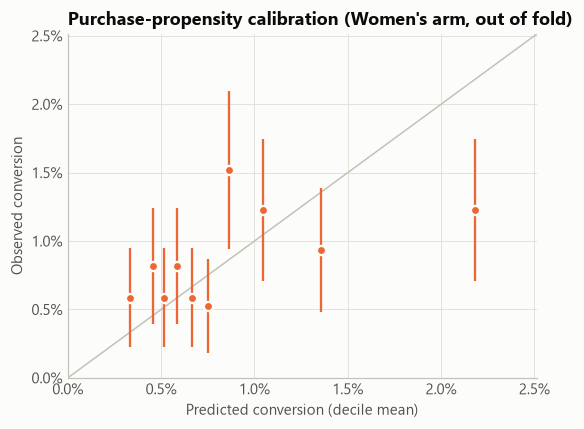

In [7]:
key = PRIMARY
p = oof[key]["Purchase propensity"]
m = (df.loc[p.index, "segment"] == config.CAMPAIGNS[key]).to_numpy()
cal = pd.DataFrame({"p": p[m].to_numpy(), "y": df.loc[p.index[m], "conversion"].to_numpy()})
cal["bin"] = pd.qcut(cal["p"].rank(method="first"), 10, labels=False)
cal = cal.groupby("bin").agg(predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size"))
cal["se"] = np.sqrt(cal.observed * (1 - cal.observed) / cal.n)

fig, ax = plt.subplots(figsize=(5.2, 4))
lim = cal[["predicted", "observed"]].max().max() * 1.15
ax.plot([0, lim], [0, lim], color=P.AXIS, lw=1)
ax.errorbar(cal.predicted, cal.observed, yerr=1.96 * cal.se, fmt="o", color=P.ORANGE, ms=6,
            mec=P.SURFACE, mew=1.5, elinewidth=1.5, capsize=0)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
P.percent(ax, "x", 1); P.percent(ax, "y", 1)
ax.set_xlabel("Predicted conversion (decile mean)"); ax.set_ylabel("Observed conversion")
ax.set_title("Purchase-propensity calibration (Women's arm, out of fold)")
ax.grid(axis="x")
fig.tight_layout(); P.savefig(fig, "02_propensity_calibration"); plt.show()

The response model is weak in absolute terms (out-of-fold AUC ≈ 0.57–0.58), which is typical for a < 1% outcome and eight coarse features. Within that range it is reasonably calibrated.

The more revealing comparison is **which group it ranks**:

* The **Women's** model ranks e-mailed buyers (AUC 0.57) better than control buyers (0.53). It has partly learned *who responds to this e-mail*, not only who buys anyway.
* The **Men's** model ranks control buyers *better* (0.62) than e-mailed buyers (0.58). It has mostly learned *who buys anyway*: the classic "sure things".

This pattern is predicted by $P(\text{buy}\mid X,\text{emailed}) = P(\text{buy}\mid X,\text{not emailed}) + \tau(X)$. A model fitted to e-mailed customers mixes baseline demand and uplift, and the mix differs by campaign.

## 4 · Baseline 2: T-learner

$\hat\tau(x) = \hat\mu_1(x) - \hat\mu_0(x)$, with one gradient-boosted regressor of spend per arm. It is the simplest learner that targets the causal quantity, but its CATE is the difference of two noisy models, each fitted to a ~0.9%-nonzero outcome.

In [8]:
tau = oof[PRIMARY]["T-learner"]
print(f"T-learner OOF CATE (Women's, spend): mean ${tau.mean():.3f}, sd ${tau.std():.3f}, "
      f"share negative {(tau < 0).mean():.1%}, 1st/99th pct ${tau.quantile(.01):.2f} / ${tau.quantile(.99):.2f}")
print(f"Observed spend ATE on dev: ${gamma['spend'][PRIMARY].mean():.3f}")

T-learner OOF CATE (Women's, spend): mean $0.495, sd $1.099, share negative 25.1%, 1st/99th pct $-2.26 / $3.95
Observed spend ATE on dev: $0.462


The T-learner predicts effects with a standard deviation of about \$1.10 around a \$0.46 average, and says a quarter of customers would spend *less* if e-mailed. Notebook 01 found only modest heterogeneity, so most of that spread is model noise. The held-out evaluation below confirms it.

## 5 · Comparing targeting policies

### 5a · Cumulative gain curves
Customers are sorted by each score. The curve shows the AIPW-estimated incremental spend per population customer from e-mailing the top φ. The **random** policy is the straight line from the origin to the treat-all point. A useful ranking bows above it.

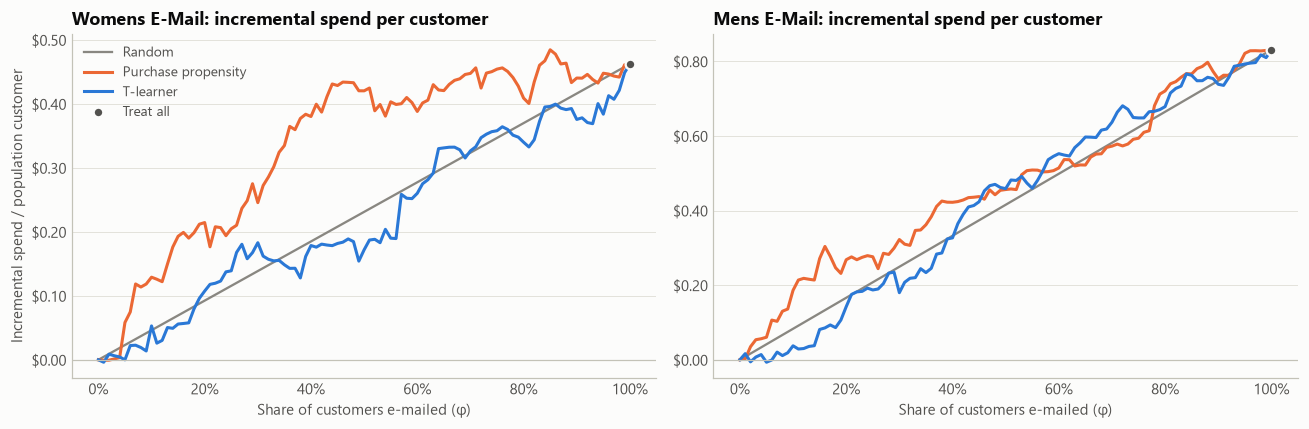

In [9]:
def plot_gain(ax, scores, g, title, money=True):
    grid = evaluation.GRID
    ax.plot([0, 1], [0, g.mean()], color=P.POLICY_COLORS["Random"], lw=1.5, label="Random")
    for name in scores:
        curve = evaluation.gain_curve(scores[name].to_numpy(), g.to_numpy())
        ax.plot(grid, curve, color=P.POLICY_COLORS[name], lw=2, label=name)
    ax.scatter([1], [g.mean()], color=P.POLICY_COLORS["Treat all"], s=40, zorder=4,
               edgecolor=P.SURFACE, linewidth=1.5, label="Treat all")
    ax.axhline(0, color=P.AXIS, lw=0.8)
    P.percent(ax, "x")
    if money:
        P.dollar(ax)
    ax.set_xlabel("Share of customers e-mailed (φ)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, CAMPAIGN_KEYS):
    plot_gain(ax, oof[key], gamma["spend"][key].loc[oof[key].index], f"{config.CAMPAIGNS[key]}: incremental spend per customer")
axes[0].set_ylabel("Incremental spend / population customer")
axes[0].legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "02_gain_curves_spend"); plt.show()

### 5b · Summary metrics
* **AUGC**: area between the gain curve and the random line, in \$ per customer averaged over coverage. 0 means no better than random.
* **gain@30%**: incremental spend per population customer when e-mailing the top 30%.
* **vs_random**: *paired* difference against random targeting at 30%, computed on the same AIPW scores, with its standard error.
* **BLP slope**: OLS slope of Γ on the predicted CATE ([Chernozhukov et al.](https://arxiv.org/abs/1712.04802)). It equals 1 for a well-scaled CATE and 0 for pure noise. It is only meaningful for models whose output is in dollars; the propensity score is a probability, so its slope is not comparable.

In [10]:
summary = {}
for key in CAMPAIGN_KEYS:
    g = gamma["spend"][key].loc[oof[key].index]
    summary[key] = pipeline.summarize_rankings(oof[key], g)
summary = pd.concat(summary, names=["campaign"])
summary

AUGC  gain@30%  gain@30%_se  vs_random  vs_random_se  BLP_slope
campaign model                                                                                 
womens   Purchase propensity  0.1052    0.2456       0.0935     0.1069        0.0743    49.8535
         T-learner           -0.0112    0.1830       0.0810     0.0443        0.0682    -0.0923
mens     Purchase propensity  0.0468    0.3220       0.1145     0.0727        0.0880    32.3258
         T-learner            0.0066    0.1800       0.0918    -0.0692        0.0766    -0.0389

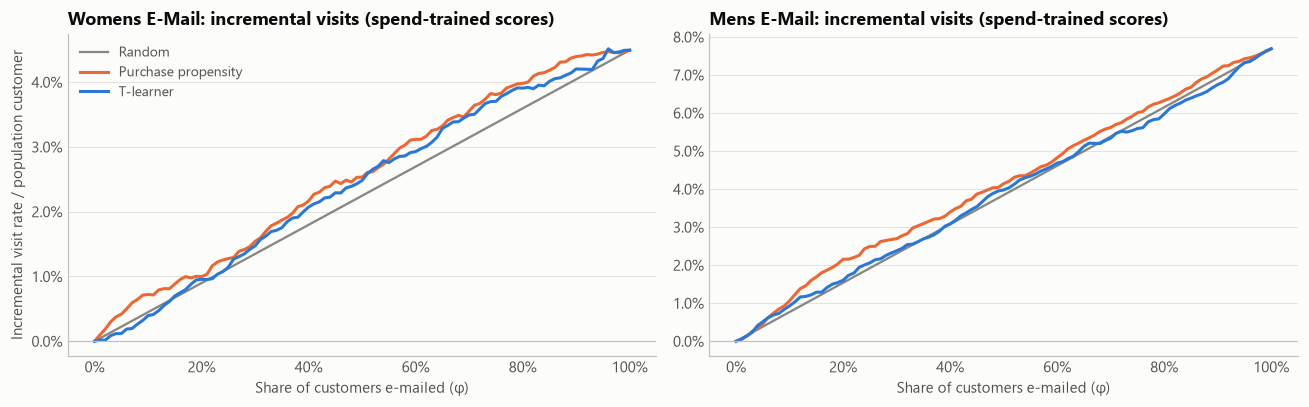

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, key in zip(axes, CAMPAIGN_KEYS):
    g = gamma["visit"][key].loc[oof[key].index]
    curve_scores = oof[key].copy()
    grid = evaluation.GRID
    ax.plot([0, 1], [0, g.mean()], color=P.POLICY_COLORS["Random"], lw=1.5, label="Random")
    for name in curve_scores:
        ax.plot(grid, evaluation.gain_curve(curve_scores[name].to_numpy(), g.to_numpy()),
                color=P.POLICY_COLORS[name], lw=2, label=name)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    P.percent(ax, "x"); P.percent(ax, "y", 1)
    ax.set_xlabel("Share of customers e-mailed (φ)")
    ax.set_title(f"{config.CAMPAIGNS[key]}: incremental visits (spend-trained scores)")
axes[0].set_ylabel("Incremental visit rate / population customer"); axes[0].legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "02_gain_curves_visit"); plt.show()

In [12]:
s = summary
display(P.md(
    f"""**What the baselines show (development set, out of fold, spend)**

* For the Women's e-mail, **purchase-propensity targeting beats random**. The top 30% by propensity deliver
  ${s.loc[('womens', 'Purchase propensity'), 'gain@30%']:.3f} of incremental spend per population customer, versus
  ${0.3 * gamma['spend']['womens'].mean():.3f} for random (paired difference ${s.loc[('womens', 'Purchase propensity'), 'vs_random']:+.3f} ± {s.loc[('womens', 'Purchase propensity'), 'vs_random_se']:.3f} se).
* The **T-learner**, despite targeting the causal quantity, is roughly **no better than random** over the whole curve
  (AUGC {s.loc[('womens', 'T-learner'), 'AUGC']:+.3f} vs {s.loc[('womens', 'Purchase propensity'), 'AUGC']:+.3f} for propensity). Its BLP slope of
  {s.loc[('womens', 'T-learner'), 'BLP_slope']:.2f} means its predicted dollar effects carry essentially no held-out signal.
* For the Men's e-mail, neither baseline separates clearly from random (paired differences within ~1 se). That matches notebook 01, where the Men's spend effect showed no detectable heterogeneity.
* On **visits**, both spend-trained scores sit only slightly above random. A score built for one KPI is not automatically good for another.
* None of these differences is large relative to its standard error. The ranking of baselines is suggestive, not conclusive, and notebook 06 tests whether it holds across repeated splits.
"""))

**What the baselines show (development set, out of fold, spend)**

* For the Women's e-mail, **purchase-propensity targeting beats random**. The top 30% by propensity deliver
  \$0.246 of incremental spend per population customer, versus
  \$0.139 for random (paired difference \$+0.107 ± 0.074 se).
* The **T-learner**, despite targeting the causal quantity, is roughly **no better than random** over the whole curve
  (AUGC -0.011 vs +0.105 for propensity). Its BLP slope of
  -0.09 means its predicted dollar effects carry essentially no held-out signal.
* For the Men's e-mail, neither baseline separates clearly from random (paired differences within ~1 se). That matches notebook 01, where the Men's spend effect showed no detectable heterogeneity.
* On **visits**, both spend-trained scores sit only slightly above random. A score built for one KPI is not automatically good for another.
* None of these differences is large relative to its standard error. The ranking of baselines is suggestive, not conclusive, and notebook 06 tests whether it holds across repeated splits.


## 6 · Why does a *non-causal* score work for spend here?

The textbook argument against propensity targeting is the **"sure things"**: customers who buy anyway are top-ranked but have zero uplift. Whether that bites depends on what the propensity model actually learned. Below, each campaign's propensity ranking is cut into quintiles. Mean spend is shown separately for **control** and **e-mailed** customers in each quintile, on the same dollar axis, so the gap is the uplift.

In [13]:
def quintile_table(key):
    p = oof[key]["Purchase propensity"]
    q = pd.qcut(p.rank(method="first", ascending=False), 5, labels=range(1, 6)).astype(int)
    seg = df.loc[p.index, "segment"]
    g = gamma["spend"][key].loc[p.index]
    rows = []
    for d in range(1, 6):
        m = (q == d).to_numpy()
        r = evaluation.mean_ci(g[m])
        rows.append({"campaign": config.CAMPAIGNS[key], "quintile": d,
                     "control_spend": df.loc[p.index[m & (seg == config.CONTROL).to_numpy()], "spend"].mean(),
                     "emailed_spend": df.loc[p.index[m & (seg == config.CAMPAIGNS[key]).to_numpy()], "spend"].mean(),
                     "uplift_AIPW": r["estimate"], "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
    return pd.DataFrame(rows)

quint = pd.concat([quintile_table(k) for k in CAMPAIGN_KEYS], ignore_index=True)
quint.set_index(["campaign", "quintile"])

control_spend  emailed_spend  uplift_AIPW  ci_low  ci_high
campaign      quintile                                                            
Womens E-Mail 1                0.5119         1.5663       1.0724  0.3383   1.8065
              2                0.6477         1.4946       0.8287  0.1350   1.5224
              3                0.7493         0.7976       0.0396 -0.5965   0.6757
              4                0.7243         0.8297       0.1042 -0.4836   0.6920
              5                0.6261         0.9004       0.2671 -0.3551   0.8893
Mens E-Mail   1                1.0880         2.4646       1.3407  0.3560   2.3253
              2                0.8331         1.5886       0.7695  0.0293   1.5097
              3                0.3839         0.8583       0.4599  0.0241   0.8956
              4                0.3811         1.4102       1.0326  0.3404   1.7248
              5                0.5642         1.1256       0.5511 -0.1333   1.2356

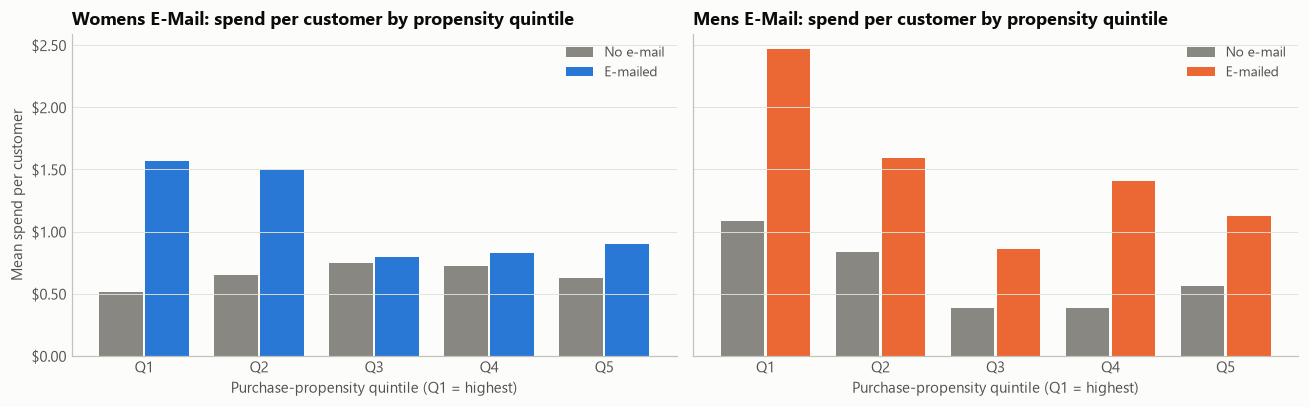

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
w = 0.38
for ax, key in zip(axes, CAMPAIGN_KEYS):
    t = quint[quint.campaign == config.CAMPAIGNS[key]]
    x = t.quintile.to_numpy()
    ax.bar(x - w / 2 - 0.01, t.control_spend, width=w, color=P.MUTED, label="No e-mail")
    ax.bar(x + w / 2 + 0.01, t.emailed_spend, width=w, color=P.CAMPAIGN_COLORS[key], label="E-mailed")
    ax.set_xticks(x, [f"Q{i}" for i in x]); ax.set_xlabel("Purchase-propensity quintile (Q1 = highest)")
    ax.set_title(f"{config.CAMPAIGNS[key]}: spend per customer by propensity quintile")
    P.dollar(ax); ax.legend(loc="upper right")
axes[0].set_ylabel("Mean spend per customer")
fig.tight_layout(); P.savefig(fig, "02_spend_by_propensity_quintile"); plt.show()

**Interpretation.**

* **Women's e-mail:** control spend is roughly flat across quintiles, while e-mailed spend is concentrated in the top quintiles. The model ranks *responsiveness*, so it behaves as an **implicit uplift model**. It works because baseline demand is barely predictable from these features, which leaves uplift as the main thing a treated-arm response model can learn.
* **Men's e-mail:** control spend also rises toward the top quintiles, so part of the ranking is buying-anyway demand ("sure things"). That is why propensity targeting has less of an edge there.

The general lesson: **a propensity model's usefulness for targeting is an empirical, campaign-specific accident**. It depends on how much of P(buy | e-mailed) is baseline demand versus uplift, which can only be checked against a randomized control group.

Two consequences carry into notebook 03:
1. Advanced uplift models have to beat a **strong, low-variance baseline**. The propensity model fits one clean conditional mean, while the T-learner differences two noisy ones.
2. Ranking is not the whole decision. Choosing **how many** customers to e-mail (break-even), and **which campaign** each gets, needs effects in **dollars** that are comparable across campaigns. A propensity score cannot provide that by itself.

## 7 · Baseline economics (development set, user-supplied assumptions)

The cells below convert gains to profit under the default assumptions: **margin = 35%** of incremental spend, **cost = \$0.10** per e-mail. Values are per 100,000 customers.

In [15]:
M, C, POP = config.MARGIN, config.COST_PER_CONTACT, config.POPULATION_SIZE
cov = evaluation.gain_at_coverage({c: oof[PRIMARY][c].to_numpy() for c in oof[PRIMARY]},
                                  gamma["spend"][PRIMARY].loc[oof[PRIMARY].index].to_numpy(), config.COVERAGE_GRID)
cov["profit_per_100k"] = (M * cov["estimate"] - C * cov["coverage"]) * POP
cov["profit_se_per_100k"] = M * cov["se"] * POP
cov.pivot(index="coverage", columns="policy", values="profit_per_100k").style.format(P.money0).format_index(
    "{:.0%}").set_caption(
    "Women's e-mail: estimated incremental profit per 100k customers (dev, out of fold)")

policy,Purchase propensity,Random,T-learner
coverage,,,
5%,"$1,541",$309,−$501
10%,"$3,519",$618,$854
20%,"$5,507","$1,237","$1,762"
30%,"$5,597","$1,855","$3,405"
40%,"$9,311","$2,474","$2,251"
50%,"$9,714","$3,092","$1,021"
60%,"$7,586","$3,710","$3,107"
70%,"$8,666","$4,329","$4,429"
80%,"$6,314","$4,947","$3,902"


## 8 · Save out-of-fold predictions for notebook 03

In [16]:
for key in CAMPAIGN_KEYS:
    oof[key].to_csv(config.ARTIFACTS_DIR / f"oof_baselines_{key}.csv")
summary.to_csv(config.ARTIFACTS_DIR / "baseline_summary.csv")
print("saved:", sorted(p.name for p in config.ARTIFACTS_DIR.glob("oof_*")))

saved: ['oof_all_mens.csv', 'oof_all_womens.csv', 'oof_baselines_mens.csv', 'oof_baselines_womens.csv', 'oof_gamma_spend.csv', 'oof_gamma_visit.csv']
